# Pathway and regulator activity

- **Question:** what does each of the 19 cell types *do*, beyond its marker
  genes — which processes, signalling pathways and transcription factors are
  active?
- **Three views of the same data**, each answering a different question:
  1. **Gene-set tests per cell type** — over-representation (ORA) of the top
     marker genes, and enrichment (GSEA) along each cell type's full gene
     ranking.
  2. **Per-cell activity scores** — signalling pathways (PROGENy) and
     transcription factors (DoRothEA), one score per cell.
  3. **The cNMF programs** from the benchmark as cluster-free gene sets.
- **Catalogues**, cached as GMT files so results cannot change between runs:
  GO Biological Process 2023 (5,406 sets), KEGG 2021 (320), Reactome 2024
  (2,100).
- **Code:** `src/pathway/`. Run order: `de_celltype` first; then `ora_markers`,
  `gsea_ranked`, `act_progeny`, `act_dorothea`, `ora_cnmf_programs` in any
  order; `pathway_report` last.
- **This notebook** only reads saved tables and figures; nothing is
  recomputed. Small summaries (counts, best rows, scaling for display) are
  taken from the saved tables. Each figure links to its full-resolution file.

In [1]:
from io import BytesIO
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display
from PIL import Image as PILImage

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURES = ROOT / "figures"
RESULTS = ROOT / "results"
MAX_PIXELS = 1600

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 60)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.precision", 3)


def show(figure: str, width: int = 900) -> None:
    """Saved figure, downscaled for display, with a link to the full file."""
    with PILImage.open(FIGURES / figure) as image:
        image.thumbnail((MAX_PIXELS, MAX_PIXELS * 4))
        buffer = BytesIO()
        image.convert("RGB").save(buffer, format="JPEG", quality=85)
    display(Image(data=buffer.getvalue(), format="jpeg", width=width),
            Markdown(f"[Full-resolution figure](../figures/{figure})"))


def table(name: str, **read_options) -> pd.DataFrame:
    """Saved results table, read from the results directory."""
    return pd.read_csv(RESULTS / name, **read_options)

## 1. Differential expression per cell type

In [2]:
top = table("pathway/de_celltype/de_celltype_top.csv")
summary = top.groupby("cell_type").agg(
    genes=("gene", "size"),
    weakest_score=("scores", "min"),
    min_log_fold_change=("logfoldchanges", "min"),
)
summary["top_6_genes"] = top.groupby("cell_type").head(6).groupby("cell_type")["gene"].agg(", ".join)
summary.sort_values("weakest_score")

,genes,weakest_score,min_log_fold_change,top_6_genes
cell_type,,,,
Platelet,200,3.614,0.685,"PF4, TMSB4X, PPBP, H3F3A, ACTB, TAGLN2"
T activated,200,5.061,0.336,"EIF1, FTH1, PIK3R1, HLA-B, MALAT1, CD69"
CD8 T cytotoxic,200,6.442,0.220,"NKG7, CCL5, GNLY, GZMH, B2M, HLA-B"
T proliferating,200,6.455,0.973,"PFN1, STMN1, ACTB, CFL1, CORO1A, PCLAF"
CD8 T memory,200,7.249,0.221,"CCL5, DUSP2, GZMK, B2M, HLA-A, IL32"
B naive,200,7.396,0.162,"CD74, HLA-DRA, CD79A, IGHM, CD37, HLA-DPB1"
Pre-B small,200,7.476,0.279,"CD79B, VPREB3, PTMA, IGHM, SOX4, HLA-DRA"
CD4 T memory,200,8.132,0.302,"IL32, LTB, TRAC, IL7R, CD3D, B2M"
CD4 T naive,200,8.451,0.216,"SARAF, EEF1A1, LTB, TRAC, CD3D, EIF3E"


- **Wilcoxon rank-sum test, each cell type against all other cells**, on the
  log-normalised counts of all genes.
- **Ribosomal, mitochondrial and haemoglobin genes are removed before the
  test**, the same rule as the marker step in the core pipeline. This also
  covers FAU, UBA52 and RACK1: ribosomal proteins whose names do not start with
  RPS or RPL. 20,455 → 20,328 genes; those 20,328 are the background for ORA.
- **Kept per cell type:** up-regulated genes (log fold change > 0) with
  adjusted p < 0.05, the 200 highest by test score.
- **All 19 cell types reach the 200-gene cap**, so the cap is binding for every
  label. `weakest_score` is the test score of the 200th gene. The strongest
  lists belong to the most distinct types: Erythroid early (45.9), HSPC (24.2),
  Monocyte classical (23.0). The weakest are Platelet (3.6, only 103 cells) and
  T activated (5.1); the large T and B labels are also weak (7.2–8.5) because
  their neighbours are similar cells.
- **The full ranked table (386,232 rows, used by GSEA) is kept on disk only**;
  it is too large for the repository.
- **Housekeeping genes lead several lists** — SARAF, EEF1A1 (CD4 T naive);
  EIF1, FTH1, MALAT1 (T activated); PFN1, ACTB, CFL1 (T proliferating); FTH1,
  FTL (Monocyte non-classical). A one-versus-rest test finds what is
  *relatively* higher, not what is specific.
- **T activated has no identity gene in its top 6**, only CD69 lower down — the
  same weakness the core pipeline found.

## 2. Over-representation of the marker lists (ORA)

In [3]:
ora = table("pathway/ora_markers/ora_markers_significant.csv")
counts = ora.groupby(["cell_type", "library"]).size().unstack(fill_value=0)
counts["total"] = counts.sum(axis=1)
counts.sort_values("total")

library,GO_BP,KEGG,Reactome,total
cell_type,,,,
CD4 T naive,38,14,55,107
B naive,98,39,38,175
Pre-B small,125,48,74,247
T activated,136,24,144,304
Plasmacytoid DC,176,58,105,339
CD4 T memory,129,74,138,341
Erythroid early,150,24,200,374
HSPC,133,36,223,392
NK,204,67,138,409


- **Test:** do the 200 marker genes overlap a gene set more than chance
  (`gseapy.enrich`, run locally on the cached sets), against a background of
  the 20,328 tested genes. 19 cell types × 3 catalogues = 57 tests;
  48,457 term results, **8,362 significant** (adjusted p < 0.05).
- **Significant terms per cell type range from 107 (CD4 T naive) to 733
  (Monocyte non-classical).** Monocytes carry the most GO terms (418 and 466);
  the dividing populations carry the most Reactome terms (T proliferating 455,
  Pre-B large 414, Erythroid late 384).
- **A long list is not a strong signal.** Every cell type returns over 100
  terms because any 200 genes overlap something; section 4 shows how few of
  these survive a stricter test.

In [4]:
best = ora.sort_values("Adjusted P-value").groupby("cell_type").head(1)
best.set_index("cell_type").sort_index()[["library", "Term", "Overlap", "Adjusted P-value"]]

,library,Term,Overlap,Adjusted P-value
cell_type,,,,
B naive,KEGG,Intestinal immune network for IgA production,15/45,2.182e-17
CD4 T memory,Reactome,Cytokine Signaling in Immune System,39/689,4.571e-16
CD4 T naive,Reactome,Generation of Second Messenger Molecules,11/37,2.849e-11
CD8 T cytotoxic,Reactome,Immunoregulatory Interactions Between a Lymphoid and a non-Lymphoid Cell,27/181,3.109e-21
CD8 T memory,Reactome,Immunoregulatory Interactions Between a Lymphoid and a non-Lymphoid Cell,26/181,6.031e-20
Dendritic cell,Reactome,Innate Immune System,61/944,1.961e-30
Erythroid early,Reactome,Cell Cycle,42/601,4.507e-21
Erythroid late,Reactome,Cell Cycle,39/601,3.739e-18
Granulocyte precursor,Reactome,Neutrophil Degranulation,39/447,7.033e-23


- **`Overlap` = marker genes in the set / genes in the set** (within the
  background).
- **Most cell types land on the expected biology**: B naive — IgA immune
  network (MHC class II, CD40 and the BAFF / APRIL receptors TNFRSF13B and
  TNFRSF13C); NK — natural killer
  cytotoxicity; Platelet — platelet activation; both CD8 labels — lymphoid /
  non-lymphoid immune interactions; Granulocyte precursor and Monocyte
  classical — neutrophil degranulation; Pre-B large, both erythroid labels —
  Cell Cycle; Pre-B small — haematopoietic cell lineage.
- **Plasmacytoid DC tops at protein processing in the endoplasmic
  reticulum**: these cells secrete large amounts of protein (interferons), so
  this is real biology rather than an identity term.
- **HSPC and T proliferating top at KEGG "Parkinson disease"** — an artefact,
  explained below.
- **T activated tops at the generic "Metabolism of RNA"** — no identity term,
  again.

In [5]:
checks = ora[
    (ora["cell_type"].eq("HSPC") & ora["Term"].isin([
        "Parkinson disease",
        "Positive Regulation Of Telomerase RNA Localization To Cajal Body (GO:1904874)",
    ]))
    | (ora["cell_type"].eq("CD4 T naive")
       & ora["Term"].eq("L13a-mediated Translational Silencing of Ceruloplasmin Expression"))
]
checks[["cell_type", "Term", "Overlap", "Adjusted P-value", "Genes"]]

,cell_type,Term,Overlap,Adjusted P-value,Genes
569,CD4 T naive,L13a-mediated Translational Silencing of Ceruloplasmin Expression,8/24,1.074e-08,EIF4B;EIF4A2;EIF2S3;EIF3L;PABPC1;EIF3H;EIF3F;EIF3E
3598,HSPC,Positive Regulation Of Telomerase RNA Localization To Cajal Body (GO:1904874),7/14,3.407e-08,NHP2;CCT8;CCT3;CCT4;CCT6A;TCP1;CCT7
3731,HSPC,Parkinson disease,19/217,8.227e-11,TUBA1B;NDUFS4;ATP5F1B;VDAC1;UQCRH;ATP5MC3;UQCRC2;NDUFB5;SEM1;TXN;ATP5PF;PSMA...


**Read the genes, not the term name**

- **KEGG neurodegeneration maps** (Parkinson, Prion, Huntington, ALS) are
  significant in 9–13 cell types each. Their genes here are respiratory-chain
  subunits (NDUF, ATP5, UQCR, COX), proteasome subunits (PSMA) and tubulins.
  Those maps are built mostly from the respiratory chain, so any metabolically
  busy cell scores. Read as *high oxidative phosphorylation and proteasome
  load*, not disease.
- **GO "Telomerase RNA localization to Cajal body"** (HSPC, both erythroid
  labels) is carried by CCT3–CCT8 and TCP1 — the CCT chaperonin, a
  protein-folding machine that the GO term happens to include. Reactome names
  the same signal plainly ("Folding of Actin by CCT TriC").
- **"L13a-mediated translational silencing" in CD4 T naive** rests on 8
  translation-initiation factors (EIF3, EIF4, PABPC1). It first ranked top
  because FAU and UBA52 — ribosomal proteins missed by the `^RP[SL]` pattern —
  were inflating it; after they were filtered it fell to third place with only
  real translation factors left.

## 3. Enrichment along the full ranking (GSEA)

In [6]:
gsea = table("pathway/pathway_report/gsea_ranked_with_leading_edge.csv")
direction = gsea["NES"].gt(0).map({True: "up", False: "down"}).rename("direction")
overview = pd.crosstab(gsea["cell_type"], direction)
overview["leading_edge_below_5"] = gsea[gsea["leading_edge_size"] < 5].groupby("cell_type").size()
overview.fillna(0).astype(int).sort_values("up")

direction,down,up,leading_edge_below_5
cell_type,,,
CD4 T naive,321,0,7
T activated,69,1,2
CD4 T memory,43,5,3
CD8 T cytotoxic,28,7,3
Plasmacytoid DC,2,14,2
Pre-B small,11,16,2
NK,22,25,3
CD8 T memory,76,28,5
B naive,226,32,5


- **Test:** does a gene set sit at the top (up) or bottom (down) of a cell
  type's full ranking of 20,328 genes, judged against 1,000 shuffles
  (`gseapy.prerank`, set size 15–500, seed 7). 74,594 term results;
  **2,837 significant** (FDR < 0.05): 1,668 up, 1,169 down.
- **`NES`** (normalised enrichment score): sign gives the direction, size the
  strength. **Leading edge**: the genes that drive the score.
- **What GSEA adds: the down side.** ORA only sees the top of a list. 41% of
  the GSEA hits are *down*.
- **CD4 T naive has 321 significant terms, every one down.** It is 28% of all
  cells, so in a one-versus-rest test its "rest" is full of related T cells.
  Nothing it does stands out as higher; it is only defined by what it lacks
  (the B, myeloid and antigen-presentation programmes of other cells).
- **T activated: 69 down, 1 up.** Same pattern, consistent with its weak
  identity.
- **T proliferating: 224 up, 0 down**, and the dividing populations (Pre-B
  large 238 up, HSPC 186, Erythroid early 162) are dominated by up terms: a
  cycling programme is a large, coherent block of genes.
- **95 significant terms have fewer than 5 leading-edge genes** (34 have only
  1 or 2). Those are not findings (below).

In [7]:
strong = gsea[gsea["leading_edge_size"] >= 5]
columns = ["Term", "NES", "leading_edge_size"]
up = strong[strong["NES"] > 0].sort_values("NES", ascending=False).groupby("cell_type").head(1)
down = strong[strong["NES"] < 0].sort_values("NES").groupby("cell_type").head(1)
pd.concat({"strongest up": up.set_index("cell_type")[columns],
           "strongest down": down.set_index("cell_type")[columns]}, axis=1).sort_index()

strongest up  \
                                                                                            Term   
cell_type                                                                                          
B naive                                                             CD22 Mediated BCR Regulation   
CD4 T memory            Immunoregulatory Interactions Between a Lymphoid and a non-Lymphoid Cell   
CD4 T naive                                                                                  NaN   
CD8 T cytotoxic         Immunoregulatory Interactions Between a Lymphoid and a non-Lymphoid Cell   
CD8 T memory            Immunoregulatory Interactions Between a Lymphoid and a non-Lymphoid Cell   
Dendritic cell                                                                            Asthma   
Erythroid early                                             Mitochondrial Translation Elongation   
Erythroid late                                                                Huntington disease   
Granulocyte precursor                                                  Oxidative phosphorylation   
HSPC                                Cross-presentation of Soluble Exogenous Antigens (Endosomes)   
Monocyte classical                                                      Neutrophil Degranulation   
Monocyte non-classical                                                                 Phagosome   
NK                                                     Natural killer cell mediated cytotoxicity   
Plasmacytoid DC                                                                           Asthma   
Platelet                                                                  Platelet Degranulation   
Pre-B large                               Formation of Tubulin Folding Intermediates by CCT TriC   
Pre-B small                                                         CD22 Mediated BCR Regulation   
T activated                            Regulation Of mRNA Splicing, Via Spliceosome (GO:0048024)   
T proliferating                            Proton Motive Force-Driven ATP Synthesis (GO:0015986)   

                                                 \
                          NES leading_edge_size   
cell_type                                         
B naive                 2.289              10.0   
CD4 T memory            1.940              25.0   
CD4 T naive               NaN               NaN   
CD8 T cytotoxic         2.295              39.0   
CD8 T memory            2.220              35.0   
Dendritic cell          1.454              11.0   
Erythroid early         1.500              79.0   
Erythroid late          2.159             119.0   
Granulocyte precursor   1.686              67.0   
HSPC                    1.518              31.0   
Monocyte classical      2.109             161.0   
Monocyte non-classical  1.747              56.0   
NK                      2.061              42.0   
Plasmacytoid DC         1.571              11.0   
Platelet                2.216              44.0   
Pre-B large             1.472              12.0   
Pre-B small             2.088              10.0   
T activated             1.865              34.0   
T proliferating         1.444              53.0   

                                                                                   strongest down  \
                                                                                             Term   
cell_type                                                                                           
B naive                                                                 Oxidative phosphorylation   
CD4 T memory                                                         CD22 Mediated BCR Regulation   
CD4 T naive                                                          CD22 Mediated BCR Regulation   
CD8 T cytotoxic                                                      CD22 Mediated BCR Regulation   
CD8 T memory                                         

- **Only terms with at least 5 leading-edge genes are shown.**
- **Strong and correct up terms:** B naive and Pre-B small — CD22-mediated B
  cell receptor regulation (NES 2.29 and 2.09); NK — natural killer
  cytotoxicity (2.06); CD8 labels — lymphoid / non-lymphoid immune interactions
  (2.22, 2.30); Platelet — platelet degranulation (2.22); Monocyte classical —
  neutrophil degranulation (2.11, 161 genes); Monocyte non-classical —
  phagosome (1.75).
- **Erythroid late — mitochondrial translation is the best-supported up result
  in the table** (GO term: 72 of 97 genes in the leading edge, NES 2.07; the
  four Reactome versions agree at 2.08). Its top hit by NES is KEGG
  "Huntington disease" (2.16, 119 genes) — the respiratory-chain artefact
  again.
- **The strongest down term in the whole table is Erythroid early against T
  cell receptor signalling** ("Translocation of ZAP-70", NES −3.14): a red-cell
  precursor is about as far from a T cell as this dataset goes.
- **Platelet and Monocyte classical are down on mRNA splicing and
  translation** (NES about −1.8 to −1.9). Platelets have no nucleus, so this is
  as it should be.
- **CD22 / BCR regulation is the strongest down term in every T label and NK** —
  the B-cell programme is the clearest thing they lack.
- **Name artefacts survive the leading-edge filter too**: Dendritic cell and
  Plasmacytoid DC top at "Asthma", whose 11 leading-edge genes are MHC class II
  (HLA-DR, -DP, -DQ, -DM) and FCER1A/FCER1G.
- **CD4 T naive has no up term at all** (the empty cells).

In [8]:
columns = ["cell_type", "library", "Term", "NES", "leading_edge_size", "Lead_genes"]
gsea[gsea["leading_edge_size"] < 3].sort_values("NES", ascending=False)[columns].head(10)

,cell_type,library,Term,NES,leading_edge_size,Lead_genes
2165,Platelet,GO_BP,Calcium Ion Import Across Plasma Membrane (GO:0098703),1.778,1,CLU
1895,Monocyte classical,Reactome,"Defective B4GALT7 Causes EDS, Progeroid Type",1.769,1,VCAN
1899,Monocyte classical,Reactome,Defective B3GALT6 Causes EDSP2 and SEMDJL1,1.758,1,VCAN
1937,Monocyte classical,Reactome,Defective B3GAT3 Causes JDSSDHD,1.686,1,VCAN
1847,Monocyte classical,GO_BP,Regulation Of Nervous System Process (GO:0031644),1.672,2,TYMP;APP
2128,Plasmacytoid DC,GO_BP,Skin Epidermis Development (GO:0098773),1.570,2,UGCG;STMN1
2130,Plasmacytoid DC,GO_BP,Establishment Of Skin Barrier (GO:0061436),1.559,2,UGCG;STMN1
911,Erythroid early,GO_BP,Regulation Of Cardiac Muscle Cell Membrane Repolarization (GO:0099623),1.521,1,KCNH2
1580,HSPC,GO_BP,Skin Epidermis Development (GO:0098773),1.501,2,STMN1;IL18
937,Erythroid early,Reactome,Voltage Gated Potassium Channels,1.500,1,KCNH2


- **Significant but carried by one or two genes**: "Cardiac muscle cell
  membrane repolarization" in Erythroid early is KCNH2 alone; "Skin
  epidermis development" in HSPC is STMN1 and IL18; three Reactome
  "Defective B4GALT7 / B3GALT6 / B3GAT3" disease terms in Monocyte classical
  are VCAN alone.
- **Rule: check the leading-edge size before believing a term.** A low FDR
  is not enough. Section 4 uses only up terms with at least 5 leading-edge
  genes.
- **Known limitation (recorded at run time, not in the saved tables):** gseapy
  warned that 20–49% of genes share a tied test score in each ranking. The ties
  are genes with no real difference, in the middle and bottom of the ranking;
  the reported terms come from the two ends and are not affected.

## 4. Where ORA and GSEA agree

In [9]:
overlap = table("pathway/pathway_report/ora_vs_gsea_overlap.csv")
by_cell_type = overlap.groupby("cell_type")[["both", "ora_only", "gsea_only"]].sum()
display(overlap.groupby("library")[["both", "ora_only", "gsea_only"]].sum())
by_cell_type.sort_values("both", ascending=False)

,both,ora_only,gsea_only
library,,,
GO_BP,161,3434,30
KEGG,276,683,92
Reactome,733,3075,323


,both,ora_only,gsea_only
cell_type,,,
Erythroid late,196,412,53
Pre-B large,189,455,41
T proliferating,179,428,40
HSPC,100,292,78
Monocyte classical,94,565,14
Monocyte non-classical,89,644,26
Erythroid early,60,314,98
Platelet,52,378,7
Dendritic cell,52,479,82


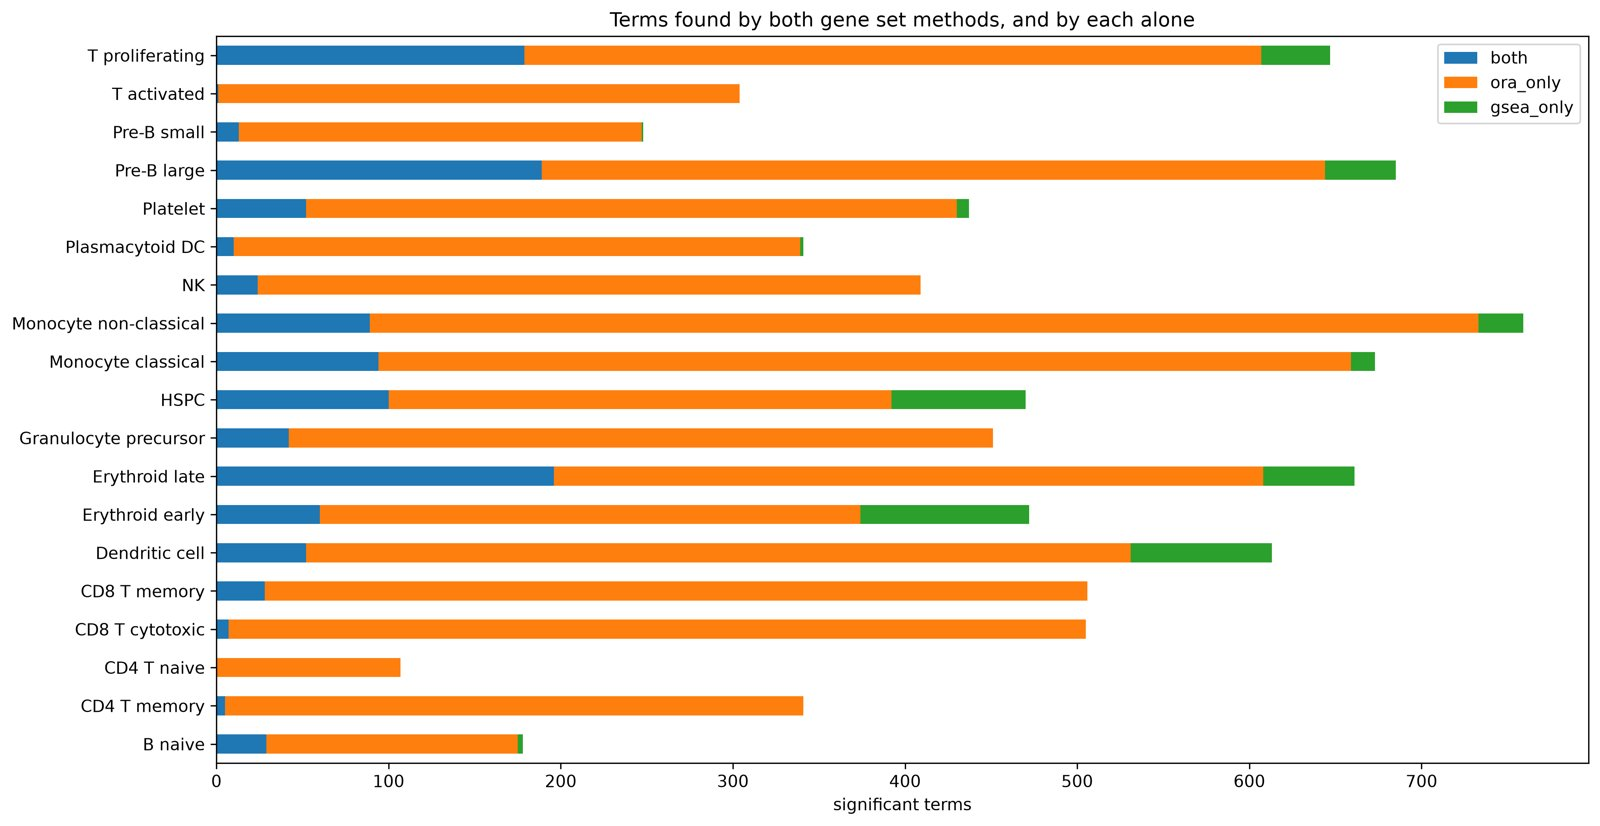

[Full-resolution figure](../figures/pathway/pathway_report/ora_vs_gsea_overlap.png)

In [10]:
show("pathway/pathway_report/ora_vs_gsea_overlap.png")

- **Counted per cell type and catalogue**: ORA significant terms against GSEA
  terms that are up and have at least 5 leading-edge genes (1,615 terms).
- **ORA finds far more in every cell type**: 8,362 ORA terms, 1,170 shared,
  445 GSEA-only.
- **Agreement is high exactly where a cell type runs one large coordinated
  programme**: Erythroid late 196 shared, Pre-B large 189, T proliferating
  179, HSPC 100, Monocyte classical 94. A whole programme (cell cycle,
  mitochondrial translation, degranulation) shifts to one end of the ranking
  *and* fills the top 200, so both methods see it.
- **Agreement collapses in the T compartment**: CD4 T naive 0 of 107, T
  activated 1 of 304, CD4 T memory 5 of 341, CD8 T cytotoxic 7 of 505. CD4 T
  naive alone is 28% of the cells, so for any T label the "rest" is full of
  other T cells, and no gene set shifts far enough for GSEA. ORA still returns
  terms because 200 genes always overlap something.
- **This is the clearest evidence in the stage that a long ORA list is not a
  strong signal.**
- **By catalogue:** GO BP gives the most ORA-only terms (3,434) and almost no
  agreement (161). Its 5,406 heavily overlapping terms are easy for a 200-gene
  list to hit and hard for a whole set to shift; the 15–500 size limit also
  excludes many of them from GSEA. KEGG and Reactome carry most of the
  agreement (276 and 733).
- **GSEA-only terms are concentrated in the progenitor and erythroid labels**
  (Erythroid early 98, Dendritic cell 82, HSPC 78): coordinated shifts of
  sets whose genes are not individually in the top 200.

## 5. Signalling pathway activity per cell (PROGENy)

In [11]:
progeny = table("pathway/act_progeny/act_progeny_by_celltype.csv", index_col="cell_type")
display((progeny.max() - progeny.min()).rename("range across cell types").sort_values().to_frame().T.round(2))
progeny.round(2)

,Androgen,Estrogen,WNT,TGFb,PI3K,NFkB,VEGF,EGFR,TNFa,Trail,MAPK,JAK-STAT,Hypoxia,p53
range across cell types,1.02,1.16,1.32,1.7,1.92,2.04,2.09,2.11,2.44,3.2,3.46,3.82,5.67,5.99


,Androgen,EGFR,Estrogen,Hypoxia,JAK-STAT,MAPK,NFkB,PI3K,TGFb,TNFa,Trail,VEGF,WNT,p53
cell_type,,,,,,,,,,,,,,
HSPC,0.16,1.00,0.26,0.17,1.24,-1.53,-1.60,-2.34,-1.64,1.23,0.43,-0.73,-0.54,-6.60
Granulocyte precursor,0.10,1.93,0.00,1.61,0.67,-1.62,-1.70,-0.80,-0.93,1.82,0.82,-0.59,-0.07,-6.35
Monocyte classical,0.33,2.13,-0.18,2.53,1.61,-2.20,-0.84,-1.41,-0.33,2.60,0.98,-0.77,0.26,-5.23
Monocyte non-classical,0.34,2.34,-0.22,2.40,2.95,-2.44,-0.62,-1.94,-0.57,2.53,0.57,-0.85,0.32,-4.85
Dendritic cell,0.34,2.38,-0.25,1.67,2.28,-2.09,-1.90,-1.32,-1.00,2.51,0.50,-0.71,0.51,-5.56
Plasmacytoid DC,0.35,1.63,-0.40,0.68,1.72,-2.48,-1.79,-1.62,-0.99,1.89,0.93,-0.65,0.24,-4.84
Erythroid early,0.33,1.09,0.65,-3.14,-0.73,0.07,-1.66,-1.24,-2.04,0.47,-1.28,-0.17,-0.81,-8.06
Erythroid late,-0.19,1.48,0.41,-1.65,-0.70,-0.62,-0.87,-0.92,-1.35,0.21,-0.00,-0.41,-0.49,-2.07
Platelet,-0.67,2.76,0.03,0.76,0.64,-3.39,-1.43,-0.83,-0.98,1.79,0.00,-0.39,0.09,-2.76


- **PROGENy** scores 14 signalling pathways from their *footprint*: the genes
  that change when a pathway is switched on, learned from perturbation
  experiments (top 500 genes per pathway). It measures the consequence of
  signalling, not the signalling molecules. 4,638 footprint genes were present
  in the data. Scored per cell with a multivariate linear model
  (`decoupler`, `dc.mt.mlm`).
- **The table is the mean score per cell type. Read down a column, never across
  a row**: each pathway has its own scale, so p53 being negative everywhere
  means nothing; only differences between cell types within a pathway count.
- **p53 tracks cell division without being told which cells divide.** Most
  suppressed in Erythroid early (−8.06), Pre-B large (−7.16), HSPC (−6.60),
  T proliferating (−6.37) and Granulocyte precursor (−6.35); least in
  Erythroid late (−2.07) and Platelet (−2.76), which have stopped dividing.
  Low p53 activity permits division.
- **Hypoxia is highest in the monocytes (2.53, 2.40) and lowest in Erythroid
  early (−3.14).** It looks backwards — red-cell production is driven by low
  oxygen — but the hypoxia footprint is mostly glycolysis genes, while
  erythroid precursors run on mitochondria (heme is made there). GSEA
  independently found mitochondrial translation up in the erythroid cells.
- **Inflammatory pathways sit with the cytokine responders**: TNFa highest in
  T proliferating (2.65), Monocyte classical (2.60), CD4 T memory (2.59);
  JAK-STAT highest in T proliferating (3.10), Monocyte non-classical (2.95),
  Dendritic cell (2.28), NK (2.25).
- **Trail is highest in B naive (1.91) and Pre-B small (1.46)**, lowest in
  Erythroid early (−1.28).
- **NFkB is highest in T activated (0.14)** — the only label above zero — and
  next in CD8 T memory (−0.14), consistent with an activation state.
- **Platelets: EGFR highest (2.76), MAPK lowest (−3.39).**
- **Androgen, Estrogen and WNT are flat** (range 1.02–1.32 across all cell
  types, against 1.70–5.99 for the rest): a useful negative control — marrow
  has no sex-hormone signalling, and the method finds none.

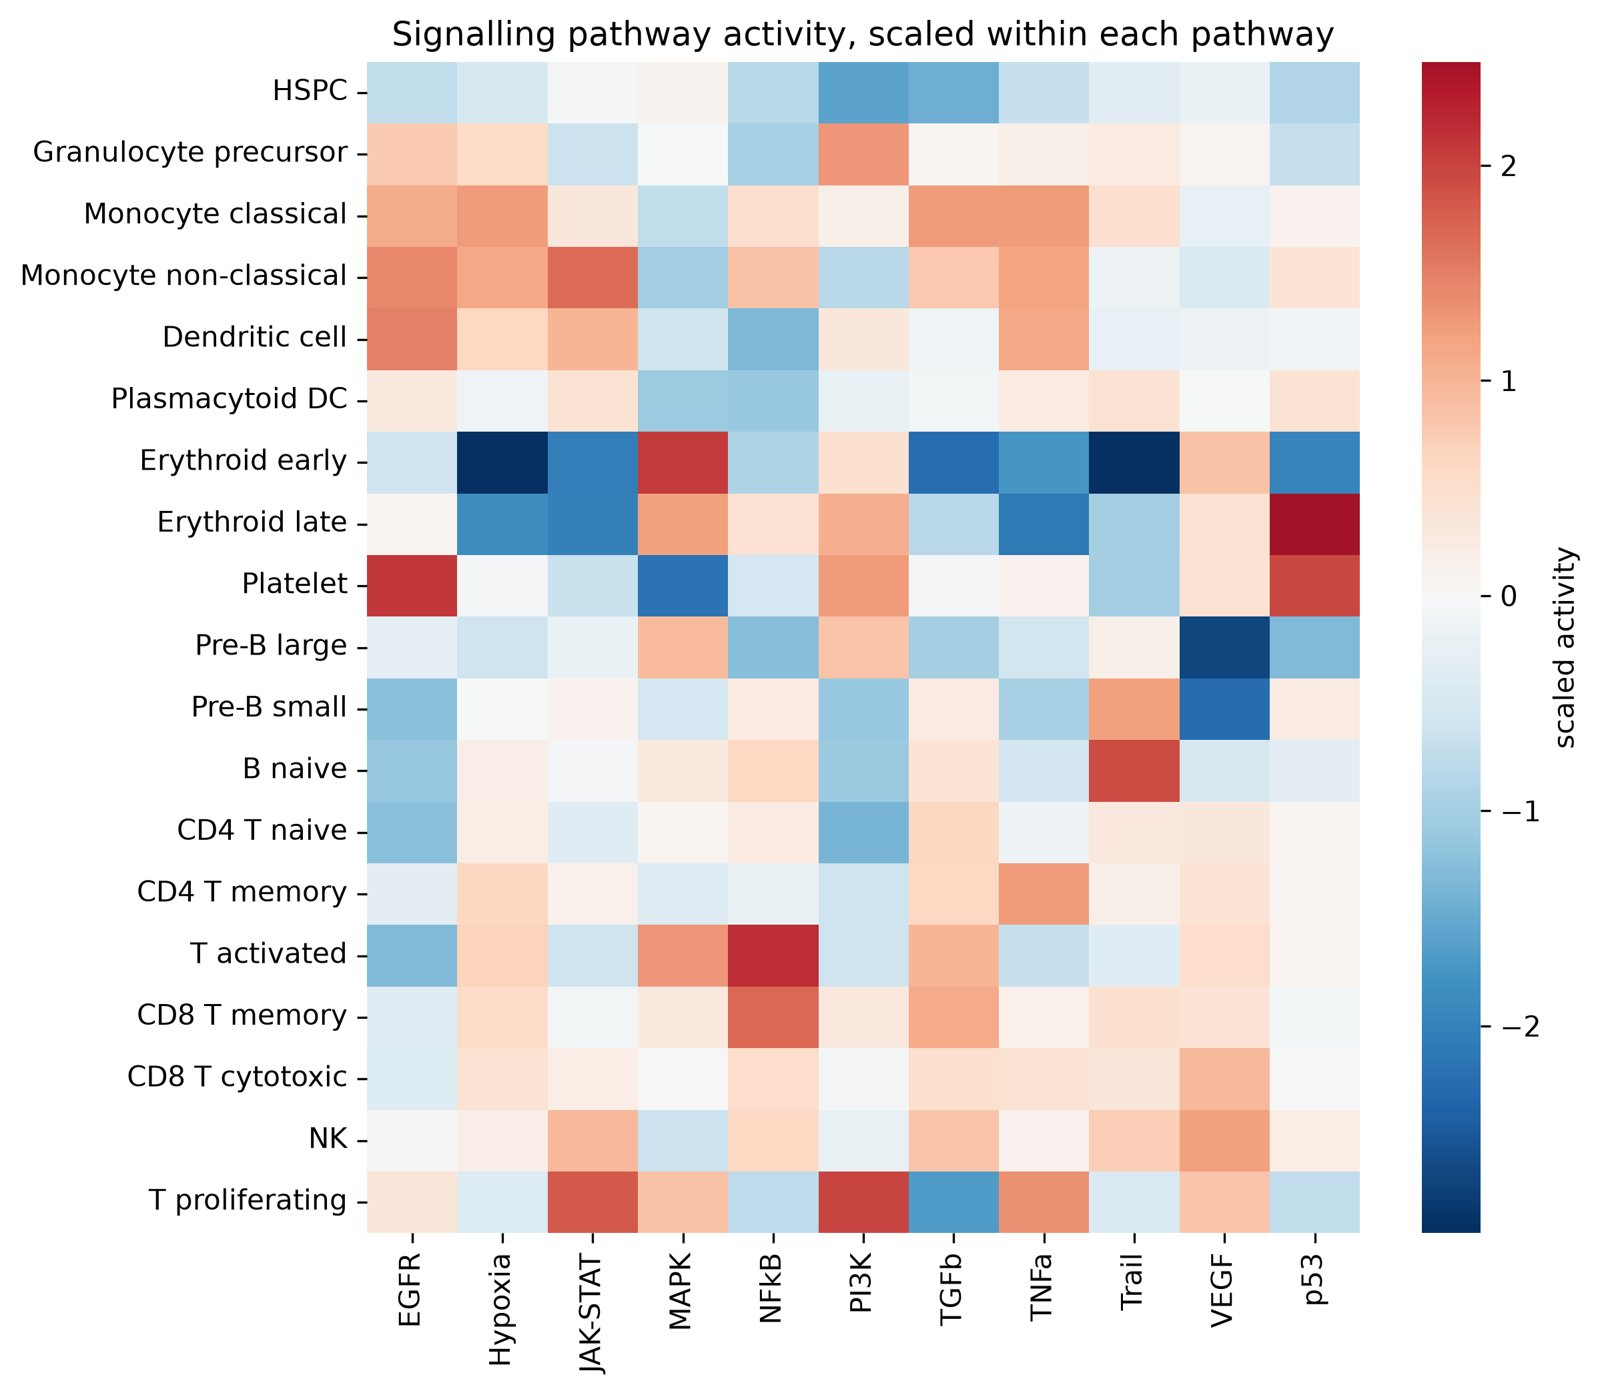

[Full-resolution figure](../figures/pathway/pathway_report/heatmap_progeny.png)

In [12]:
show("pathway/pathway_report/heatmap_progeny.png", width=650)

- **Each pathway is scaled across the 19 cell types** (mean 0, standard
  deviation 1), so the colours show *which cell types are high or low on that
  pathway*, not how strong the pathway is.
- **Flat pathways are dropped first** (raw range below 1.5: Androgen, Estrogen,
  WNT). Scaling would otherwise stretch their noise across the full colour bar.
  11 pathways remain.
- **The strong cells match the table**: Erythroid early deep blue on Hypoxia,
  Trail, JAK-STAT, TGFb and p53, red on MAPK; Erythroid late and Platelet red on
  p53; Platelet red on EGFR, blue on MAPK; B naive red on Trail; T activated and
  CD8 T memory red on NFkB; Pre-B large and small blue on VEGF; T proliferating
  red on JAK-STAT and PI3K.

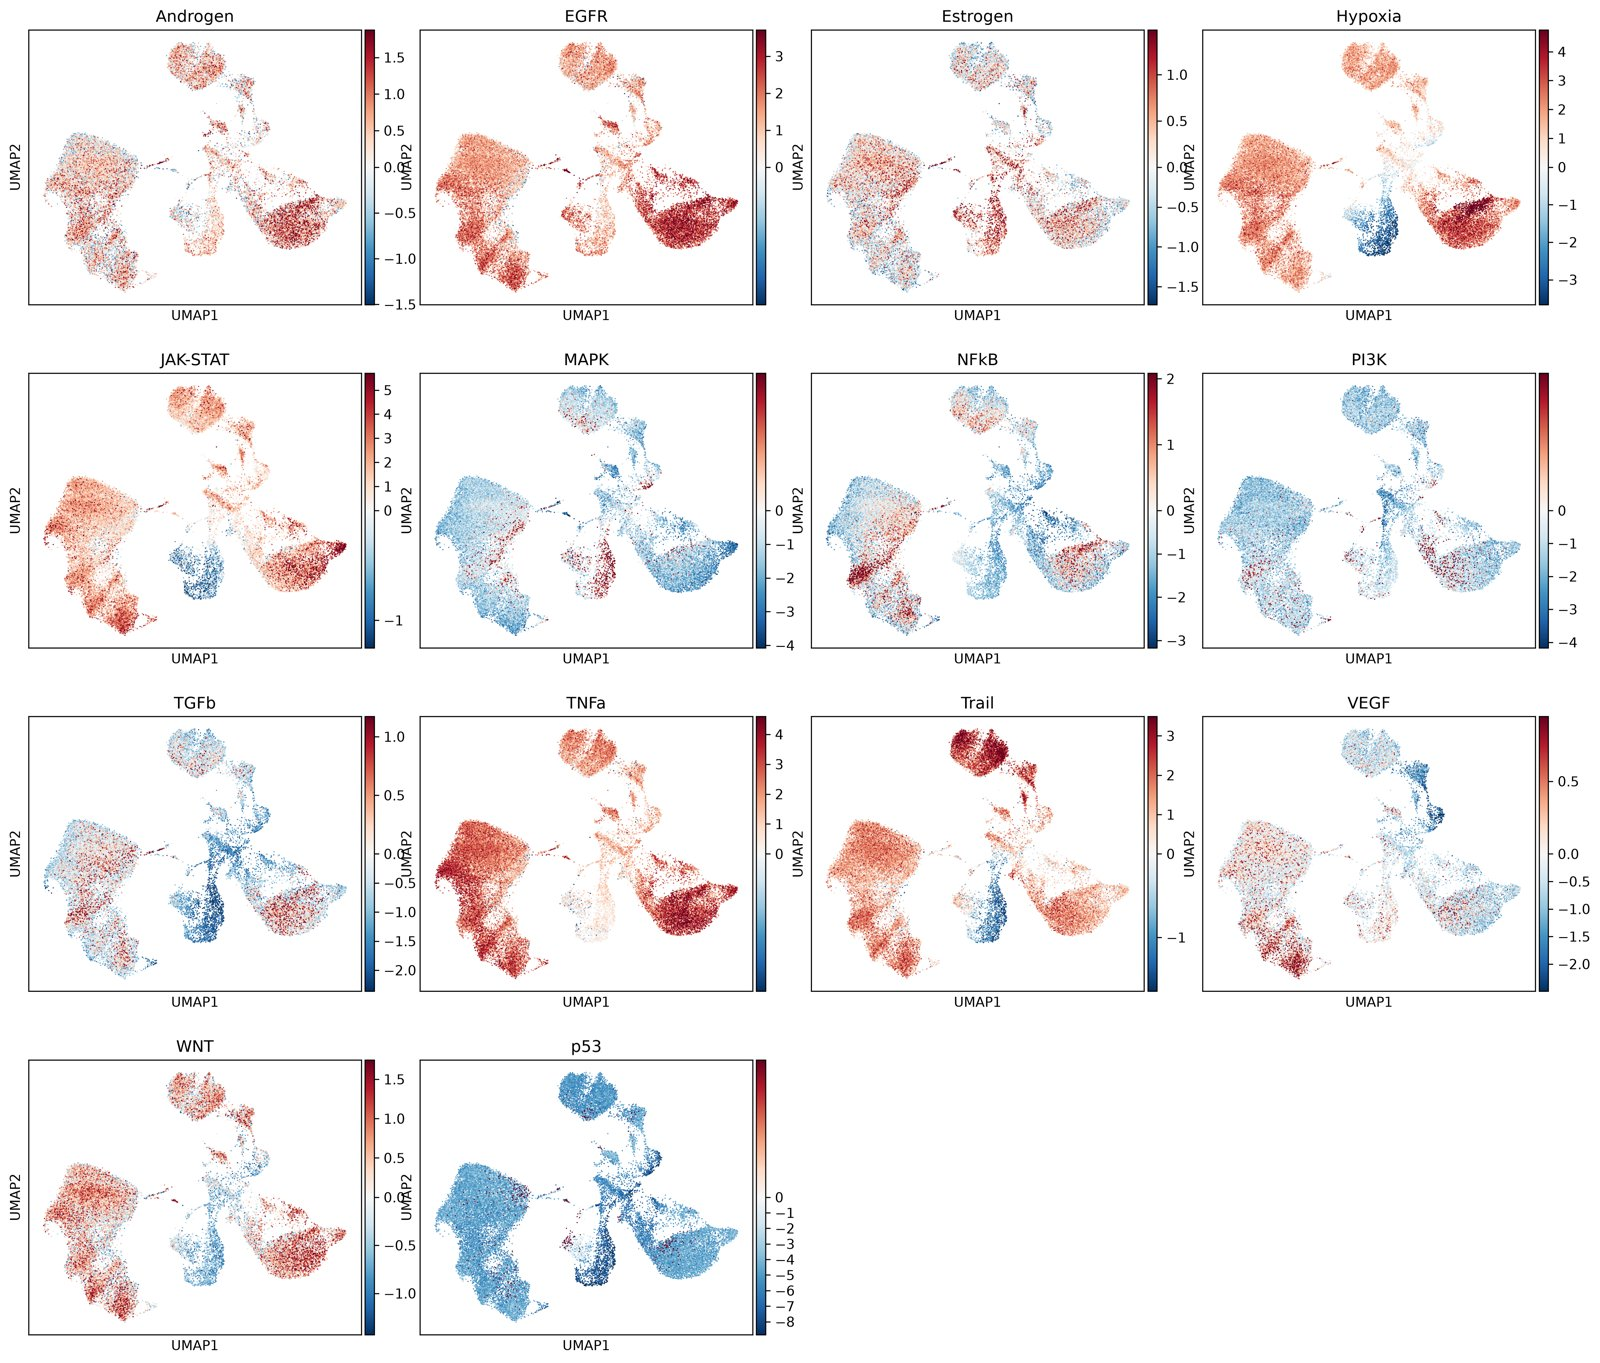

[Full-resolution figure](../figures/pathway/pathway_report/umap_progeny.png)

In [13]:
show("pathway/pathway_report/umap_progeny.png")

- **One panel per pathway, one score per cell.** Each panel has its own colour
  scale, clipped to the 1st–99th percentile and centred at 0, so colours
  compare cells *within* a panel only.
- **The four regions are recognisable from the pathways alone**: the erythroid
  island (deep blue on Hypoxia, JAK-STAT and p53), the monocyte region (red on
  Hypoxia, TNFa and EGFR), the B region (red on Trail), the T region.
- **Activity follows cell identity, not sub-structure.** Nearly every panel is
  flat inside each region and changes only between regions. The per-cell map
  was drawn to look for states that cut across cell types; there are few. This
  is a real negative result.
- **Exceptions inside a region**: the erythroid island splits on Hypoxia and
  p53, along the early / late boundary that clustering found; a bright NFkB
  streak runs through the T region where T activated sits.
- **Androgen, Estrogen and WNT still show speckled structure here** though they
  are flat in the heatmap: the heatmap compares cell-type *means*, which barely
  differ; the map shows the spread of single cells.

## 6. Transcription factor activity per cell (DoRothEA)

In [14]:
dorothea = table("pathway/act_dorothea/act_dorothea_by_celltype.csv", index_col="cell_type")
display(dorothea.idxmax(axis=1).value_counts().rename("raw top factor").to_frame().T)
scaled = (dorothea - dorothea.mean()) / dorothea.std()
pd.DataFrame({
    label: [f"{factor} {value:.1f}" for factor, value in row.nlargest(5).items()]
    for label, row in scaled.iterrows()
}, index=range(1, 6)).T

,MYC
raw top factor,19


,1,2,3,4,5
HSPC,XBP1 2.0,NCOA3 2.0,ARNT 1.8,HINFP 1.7,HIC1 1.6
Granulocyte precursor,LEF1 3.1,MYB 2.9,XBP1 1.9,ATF6 1.8,CEBPE 1.7
Monocyte classical,CEBPB 3.0,ETS2 2.5,IRF8 2.5,AHR 2.5,FOXL2 2.2
Monocyte non-classical,FOXO3 3.0,NR1H3 2.8,HNF4G 2.6,BHLHE40 2.5,PPARG 2.4
Dendritic cell,RFX5 2.2,SNAI1 2.2,FOSL1 2.2,NR2F6 2.1,VDR 2.0
Plasmacytoid DC,RARG 3.4,IRF9 3.0,ETV1 2.5,ZNF384 2.3,TP63 2.2
Erythroid early,ZHX1 3.2,SNAPC4 3.0,SIX5 2.8,THAP11 2.8,KLF1 2.7
Erythroid late,SIX5 2.0,GATA1 1.9,KLF1 1.9,GLI2 1.2,HSF1 1.0
Platelet,RFX2 3.6,PAX6 3.3,ESRRA 3.2,NFE2L1 3.2,ZKSCAN1 3.0
Pre-B large,SMAD5 2.9,E2F5 2.6,KMT2B 2.4,MYBL2 2.4,E2F2 2.3


- **DoRothEA regulons, confidence levels A–C** (levels D–E are mostly
  computational predictions). 429 factors, 32,286 interactions; **293 factors
  scored** after removing those with too few targets in the data, over 8,059
  genes. Univariate linear model per factor (`dc.mt.ulm`) — each factor is
  judged on its own regulon.
- **The raw ranking is useless: MYC is the top factor in all 19 cell types.**
  Factors with large regulons of broadly expressed genes score high
  everywhere; raw scores are not comparable between factors.
- **The table shows the top 5 factors per cell type after scaling each factor
  across cell types** (scaled value after the name).
- **Most cell types get their textbook regulators, without being told the
  labels**:
  - B naive — TCF7L1, SPIB, PAX5, with IRF4 in the top 5;
  - NK — STAT5A, STAT5B (IL-2 / IL-15 signalling), STAT4;
  - Monocyte classical — CEBPB, ETS2, IRF8;
  - Monocyte non-classical — FOXO3, NR1H3, HNF4G, BHLHE40, PPARG (the
    lipid-sensing factors of patrolling monocytes);
  - Dendritic cell — RFX5, the master regulator of MHC class II;
  - Plasmacytoid DC — RARG, IRF9 (interferon response);
  - Erythroid late — SIX5, GATA1, KLF1; Erythroid early — KLF1 in its top 5;
  - Granulocyte precursor — LEF1, MYB, with CEBPE fifth;
  - Pre-B large — SMAD5, E2F5, MYBL2, E2F2 (cell cycle);
  - CD8 labels — SATB1, ATF3, REL, STAT4; CD4 labels — TCF7, GLI1.
- **Three rows have no recognisable factor**: HSPC (XBP1, NCOA3, ARNT — no
  GATA2, TAL1 or HOXA9), T activated (FOXJ2, ZNF592, HMBOX1) and Pre-B small
  (ZC3H8, DUX4, MEIS1, POU5F1; only HHEX fifth is a known B factor).
- **One factor is biologically suspect**: PAX6, an eye-development factor,
  scores second in Platelet — regulon overlap with megakaryocyte genes, not real
  activity.
- **CD4 T naive's top scaled value is only 1.6**: the largest label has
  nothing that sets it apart, as in GSEA.

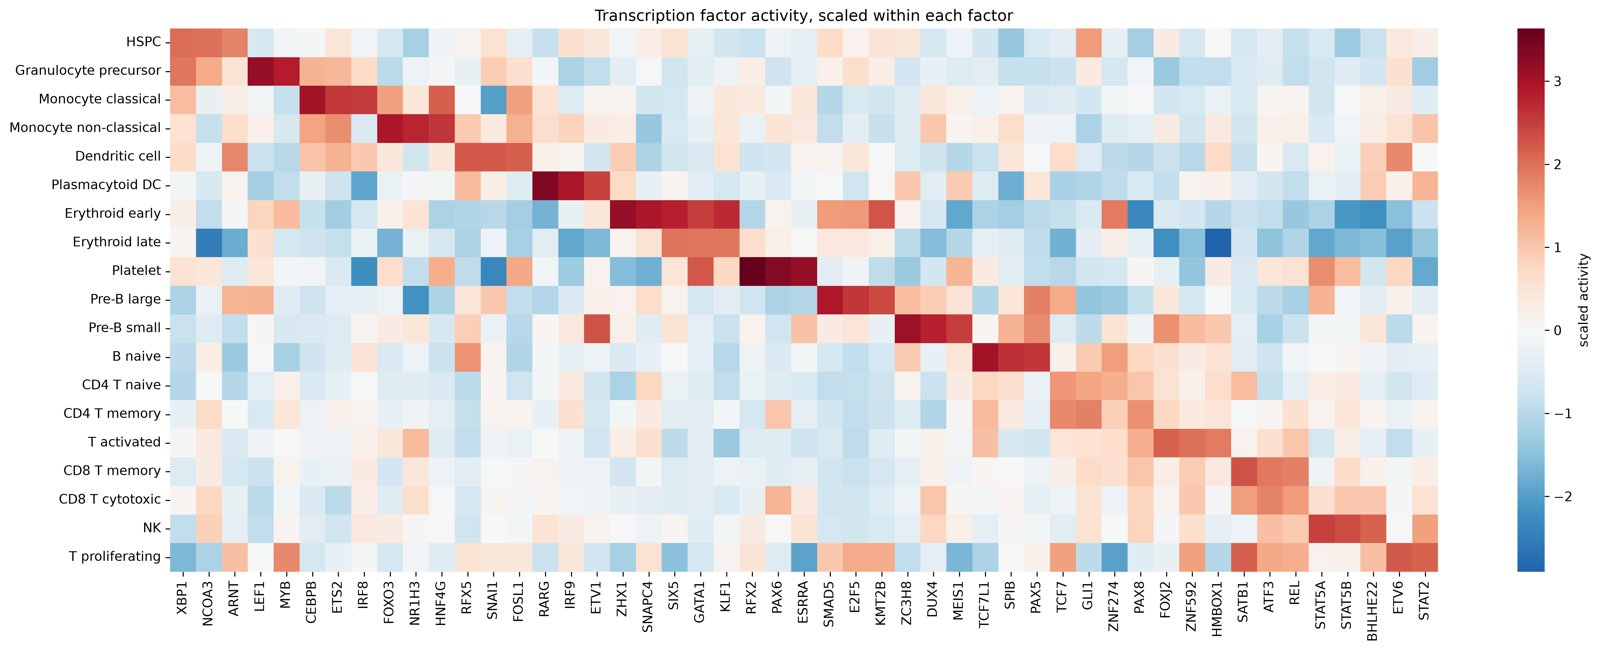

[Full-resolution figure](../figures/pathway/pathway_report/heatmap_dorothea.png)

In [15]:
show("pathway/pathway_report/heatmap_dorothea.png")

- **The 3 highest scaled factors of each cell type, 49 factors in all.**
- **A clean diagonal band**: each cell type owns its own block of factors, and
  the blocks follow the lineage order down the rows. This is the strongest
  independent confirmation of the annotation in the stage — the regulons come
  from a database built on entirely different experiments.
- **The same three rows break the pattern**: HSPC pale across its row,
  T activated with a weak FOXJ2 / ZNF592 / HMBOX1 patch, Pre-B small resting on
  ZC3H8, DUX4 and MEIS1.
- **Shared blocks are biology**: SIX5, GATA1 and KLF1 light up in both
  erythroid rows; SATB1, ATF3 and REL across the CD8 rows, SATB1 also in
  T proliferating; TCF7 and GLI1 across the CD4 rows.

## 7. cNMF programs as gene sets

In [16]:
cnmf = table("pathway/ora_cnmf_programs/ora_cnmf_significant.csv")
cnmf.groupby("program").size().rename("significant terms").to_frame().T

program,program_01,program_02,program_03,program_04,program_05,program_06,program_07,program_08,program_09,program_11,program_12,program_13,program_14,program_15,program_16,program_18,program_19,program_20,program_21,program_22,program_23,program_24,program_25,program_26,program_27,program_29,program_30
significant terms,64,63,63,77,8,1,97,32,205,5,3,241,17,43,25,78,4,6,1,62,228,4,43,41,89,59,40


- **The 30 cNMF programs from the benchmark tested as gene sets** (top 100
  genes each, against the 2,000 genes cNMF was fitted on). 1,599 significant
  terms; **27 of 30 programs have at least one.**
- **The three without a term are 10 (HSPC), 17 (plasmacytoid DC) and 28 (mast
  cells / basophils)**: programs defined by rare cell *identity*. Gene-set
  catalogues describe processes, not stem or rare-cell identities.
- **Confirmations**: the cell-cycle programs 13 and 23 (Cell Cycle, 58/163 and
  52/139), heat shock 15 (unfolded-protein response, 9/9), plasma cells 22
  (FCGR activation, 14/19), macrophages 30 (cholesterol / lipid handling), and
  program 1 as the translation axis (rRNA processing).
- **The per-program reading is in the benchmark notebook** (section 5).

## 8. Conclusions

- **The 19 labels are confirmed three independent times** — by curated gene
  sets, by PROGENy footprints and by DoRothEA regulons. None of the three was
  given the labels.
- **T activated is the weakest label**: no identity gene in its markers, only a
  generic RNA term from ORA, 1 term shared between ORA and GSEA, 69 of 70 GSEA
  hits down, no distinctive transcription factor.
- **HSPC is the hardest population for these methods**: its strongest ORA term
  is an artefact, no distinctive transcription factor, no gene-set term for its
  cNMF program. Its identity rests on marker genes (SPINK2, AVP, CRHBP, CD34).
- **CD4 T naive is defined only by what it lacks**: 0 up terms in GSEA,
  0 agreement with ORA, weakest scaled factor. The cause is its size (28% of
  cells) in a one-versus-rest design.
- **Signalling activity follows cell identity**; the per-cell maps show little
  structure inside cell types.
- **Rules carried forward**:
  - read the genes behind a term before the term's name;
  - require at least 5 leading-edge genes;
  - scale an activity score within a feature across cell types, never across
    features;
  - a long ORA list is not evidence of a strong signal;
  - keep MRPL / MRPS genes: in erythroid cells the mitochondrial machinery is
    real biology.